<a href="https://colab.research.google.com/github/fischdakid/is-4487-labs/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load data from GitHub
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

# Show the first few rows
display(df.head())

# Data types / missing values
df.info()

# Summary statistics
display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal                            94

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.What stands out to me in this dataset is that it is very large. There are a lot of missing calues with company and agent being pretty much empty. adr also has a number of weird values like a booking with a negative average daily rate. There are also bookings with zero adults which doesnt make sense.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [4]:
# Add code here 🔧
# 2.2 Basic data prep on the full dataframe
df_clean = df.copy()

# Remove duplicate rows
print("Rows before removing duplicates:", len(df_clean))
df_clean = df_clean.drop_duplicates()
print("Rows after removing duplicates:", len(df_clean))

# Correct datatypes
df_clean['reservation_status_date'] = pd.to_datetime(df_clean['reservation_status_date'])
df_clean['agent'] = df_clean['agent'].astype(str)      # IDs, not numbers
df_clean['company'] = df_clean['company'].astype(str)  # IDs, not numbers

# Create a total nights feature
df_clean['total_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']

# 2.1 Select features
features = ['lead_time', 'total_nights', 'adr', 'total_of_special_requests']

# 2.3 Drop missing values in the selected features
df_clean = df_clean.dropna(subset=features)

# 2.2 Remove bad rows and outliers
df_clean = df_clean[df_clean['adults'] > 0]                                    # bookings with no adults
df_clean = df_clean[(df_clean['adr'] > 0) & (df_clean['adr'] < 1000)]          # negative/zero/extreme prices
df_clean = df_clean[(df_clean['total_nights'] > 0) & (df_clean['total_nights'] <= 30)]  # 0-night or very long stays
df_clean = df_clean[df_clean['lead_time'] <= df_clean['lead_time'].quantile(0.99)]      # top 1% lead times
print("Rows after cleaning:", len(df_clean))

# Feature dataframe
X = df_clean[features]
display(X.describe())

# 2.4 Standardize (lead_time and adr go over 100; scaling all features keeps them on equal footing)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)
display(X_scaled_df.head())

Rows before removing duplicates: 9404
Rows after removing duplicates: 7730
Rows after cleaning: 7440


,lead_time,total_nights,adr,total_of_special_requests
count,7440.000000,7440.000000,7440.000000,7440.000000
mean,61.883199,4.353360,93.537980,0.689651
std,70.076448,3.264477,54.209961,0.855810
min,0.000000,1.000000,2.000000,0.000000
25%,5.000000,2.000000,48.000000,0.000000
50%,37.000000,4.000000,78.700000,0.000000
75%,91.000000,7.000000,130.000000,1.000000
max,292.000000,29.000000,508.000000,5.000000


,lead_time,total_nights,adr,total_of_special_requests
2,-0.783243,-1.027296,-0.341989,-0.805900
3,-0.697616,-1.027296,-0.341989,-0.805900
4,-0.683345,-0.720948,0.082316,0.362663
6,-0.883141,-0.720948,0.248348,-0.805900
7,-0.754701,-0.720948,0.174556,0.362663


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. The features I chose are lead time, total nights, adr, and total of special requests since together they capture how far out someone is planning a trip, what they are spending, and what demands they have. These are the key things for a hotel marketing team to focus on.

2. I am expecting to find the segments like last minute booking for business people, early planners for vacation long stays, the premium guests who are paying for uprades and add ons, and lastly, the budget guests who are driven mostly by price.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

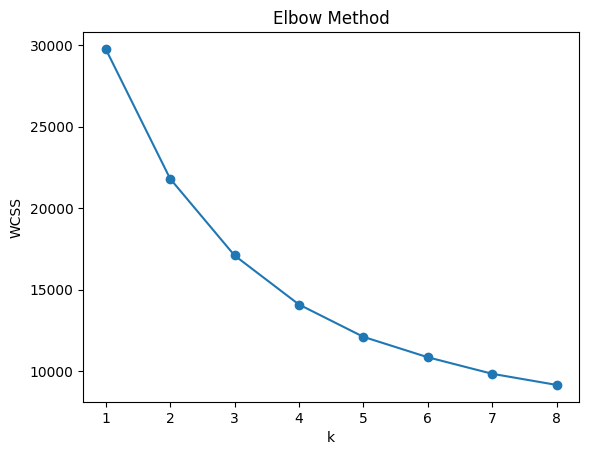

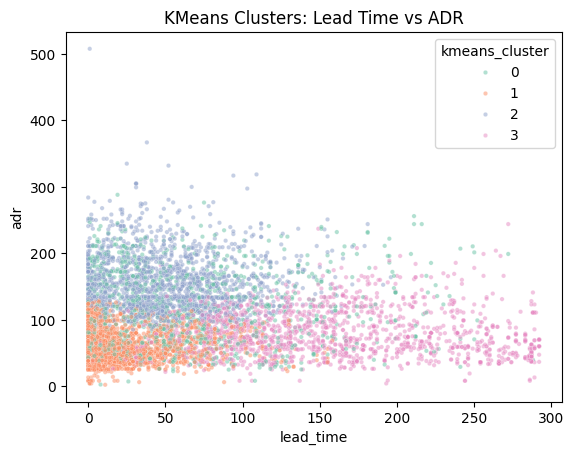

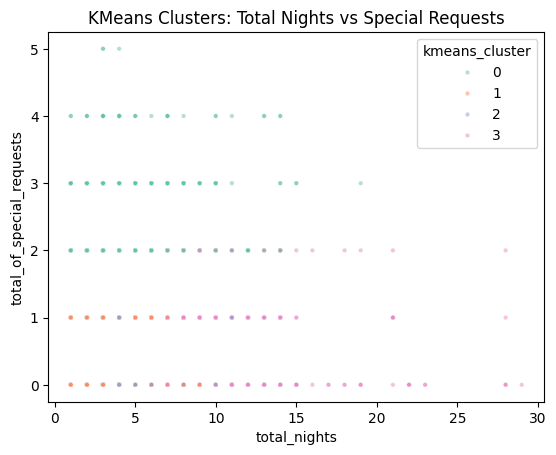

,lead_time,total_nights,adr,total_of_special_requests,count
kmeans_cluster,,,,,
0,62.38,4.47,113.40,2.25,1201
1,18.06,2.36,56.07,0.32,2943
2,49.23,4.76,156.48,0.45,1746
3,158.96,7.59,78.38,0.44,1550


In [5]:
# Elbow method to help choose k
wcss = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 9), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.show()

# Fit KMeans with k = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_clean['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# Scatterplot 1
sns.scatterplot(data=df_clean, x='lead_time', y='adr', hue='kmeans_cluster', palette='Set2', alpha=0.5, s=10)
plt.title('KMeans Clusters: Lead Time vs ADR')
plt.show()

# Scatterplot 2
sns.scatterplot(data=df_clean, x='total_nights', y='total_of_special_requests', hue='kmeans_cluster', palette='Set2', alpha=0.5, s=10)
plt.title('KMeans Clusters: Total Nights vs Special Requests')
plt.show()

# Summary table
kmeans_summary = df_clean.groupby('kmeans_cluster')[features].mean().round(2)
kmeans_summary['count'] = df_clean['kmeans_cluster'].value_counts().sort_index()
display(kmeans_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I did K=4 because the elbow plot flattens out around 4 along with the four clusters being easy to tell apart or explain to people.

2.

Cluster A: The last minute bookings for short stays, these have low lead time, only a few nights, and likely for business.

Cluster B: These are the people with a long lead time and typically longer stays. Likely people booking vacations for out in advance.

Cluster C: The premium guests with highest ADR. These people pay for better rooms or peak season dates.

Cluster D: High touch guests who have the most special requests. This could be families who need a crib for baby or people with specific parking or room preferences.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

,prob_cluster_0,prob_cluster_1,prob_cluster_2,prob_cluster_3
2,0.007,0.490,0.500,0.003
3,0.014,0.000,0.979,0.007
4,0.157,0.000,0.838,0.005
6,0.018,0.023,0.955,0.004
7,0.161,0.003,0.832,0.004


Share of guests with < 70% confidence: 0.158


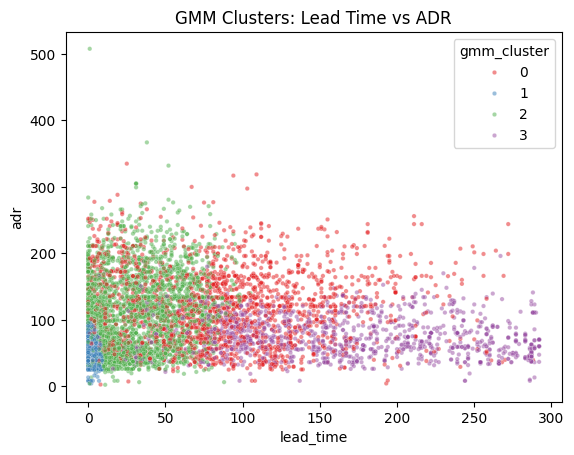

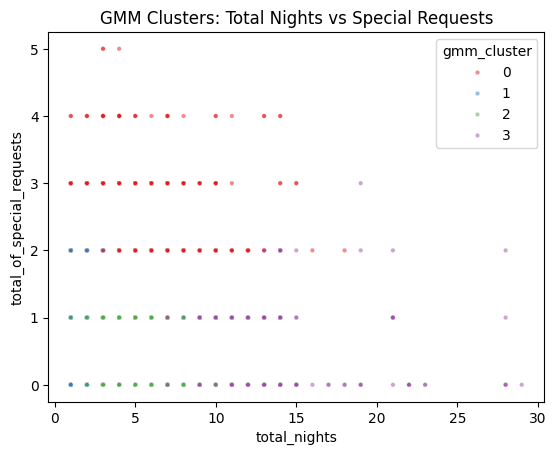

,lead_time,total_nights,adr,total_of_special_requests,gmm_confidence,count
gmm_cluster,,,,,,
0,86.86,5.00,120.11,1.72,0.88,1887
1,1.93,1.38,47.59,0.40,0.95,1472
2,31.77,4.09,108.31,0.34,0.84,2841
3,164.05,7.50,73.80,0.26,0.86,1240


In [6]:
# Add your code here
# Fit GMM with the same k as KMeans
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(X_scaled)

# Soft clusters: probability of each guest belonging to each cluster
probs = gmm.predict_proba(X_scaled)
prob_df = pd.DataFrame(probs, columns=[f'prob_cluster_{i}' for i in range(4)], index=df_clean.index).round(3)
display(prob_df.head())

# Hard label (most likely cluster) + confidence for plotting/summary
df_clean['gmm_cluster'] = probs.argmax(axis=1)
df_clean['gmm_confidence'] = probs.max(axis=1)

# How many guests are "uncertain" (no cluster above 70%)
print("Share of guests with < 70% confidence:", round((df_clean['gmm_confidence'] < 0.7).mean(), 3))

# Scatterplot 1
sns.scatterplot(data=df_clean, x='lead_time', y='adr', hue='gmm_cluster', palette='Set1', alpha=0.5, s=10)
plt.title('GMM Clusters: Lead Time vs ADR')
plt.show()

# Scatterplot 2
sns.scatterplot(data=df_clean, x='total_nights', y='total_of_special_requests', hue='gmm_cluster', palette='Set1', alpha=0.5, s=10)
plt.title('GMM Clusters: Total Nights vs Special Requests')
plt.show()

# Summary table
gmm_summary = df_clean.groupby('gmm_cluster')[features + ['gmm_confidence']].mean().round(2)
gmm_summary['count'] = df_clean['gmm_cluster'].value_counts().sort_index()
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1.
 The GMM had a similar outcome to the Kmeans overall but the differences were the boudaries and cluster sizes. The Kmeans gives all guests one cluster which assumes that they are similar in size. The GMM on the other hand allows for an oval shaped clusters with different sizes giving guests a probability for every cluster. The Kmean hides the fact that some guests had low confidence scores.

2.
GMM does a good job of answering questions like: which guests are between budget and premium and might respond to an upgrade offer? or how confident are we in a segment before spending marketing money on it?or which customers have mixed behavior that one label would oversimplify?


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [7]:
# Add code here 🔧
# Labels from both models
km_labels = df_clean['kmeans_cluster'].values
gmm_labels = df_clean['gmm_cluster'].values

# WCSS function (sum of squared distances from each point to its cluster center)
def calc_wcss(X, labels):
    total = 0
    for c in np.unique(labels):
        points = X[labels == c]
        center = points.mean(axis=0)
        total += ((points - center) ** 2).sum()
    return total

# Random 10K sample for the slower metrics
rng = np.random.default_rng(42)
idx = rng.choice(len(X_scaled), size=min(10000, len(X_scaled)), replace=False)
X_sample = X_scaled[idx]

results = pd.DataFrame({
    'Model': ['KMeans', 'GMM'],
    'WCSS': [calc_wcss(X_scaled, km_labels), calc_wcss(X_scaled, gmm_labels)],
    'Silhouette Score': [silhouette_score(X_sample, km_labels[idx]),
                         silhouette_score(X_sample, gmm_labels[idx])],
    'Davies-Bouldin Index': [davies_bouldin_score(X_scaled, km_labels),
                             davies_bouldin_score(X_scaled, gmm_labels)]
}).round(3)

display(results)

,Model,WCSS,Silhouette Score,Davies-Bouldin Index
0,KMeans,14081.718,0.315,1.202
1,GMM,17214.120,0.151,1.538


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2.
Kmeans seemed to perform better on all metrics. It had a lower WCSS, higher sillouette score, and lower davies bouldin index. The clusters Kmeans provides are tighter and better seperated than GMM's. GMM's clusters suggest a lot fo overlap.


5.3.

I'd tend to recommend the Kmeans for a business analyst. It runs faster, scores better, and is more simple to explain to management. Because each guest lands in a specific segment its simple to target that with a campaign. GMM is mostly useful for finding out how confident the model is on a given guest.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

,lead_time,total_nights,adr,total_of_special_requests,total_guests,children,is_canceled,is_repeated_guest,is_resort,count,pct_of_guests
kmeans_cluster,,,,,,,,,,,
2,49.23,4.76,156.48,0.45,2.30,0.25,0.24,0.02,1.0,1746,23.5
0,62.38,4.47,113.40,2.25,2.21,0.16,0.20,0.07,1.0,1201,16.1
3,158.96,7.59,78.38,0.44,1.96,0.06,0.23,0.02,1.0,1550,20.8
1,18.06,2.36,56.07,0.32,1.67,0.05,0.10,0.16,1.0,2943,39.6


,lead_time,total_nights,adr,total_of_special_requests,total_guests,children,is_canceled,is_repeated_guest,is_resort,count,pct_of_guests
kmeans_cluster,,,,,,,,,,,
2,49.230000,4.760000,156.480000,0.450000,2.300000,0.250000,0.240000,0.020000,1.000000,1746,23.500000
0,62.380000,4.470000,113.400000,2.250000,2.210000,0.160000,0.200000,0.070000,1.000000,1201,16.100000
3,158.960000,7.590000,78.380000,0.440000,1.960000,0.060000,0.230000,0.020000,1.000000,1550,20.800000
1,18.060000,2.360000,56.070000,0.320000,1.670000,0.050000,0.100000,0.160000,1.000000,2943,39.600000


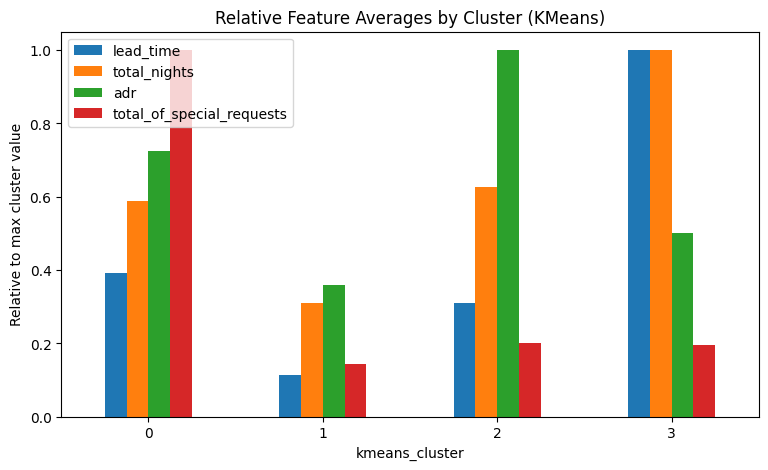

In [8]:
# Add code here 🔧
# Add a few extra columns to help describe each segment
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'] + df_clean['babies']
df_clean['is_resort'] = (df_clean['hotel'] == 'Resort Hotel').astype(int)

profile_cols = features + ['total_guests', 'children', 'is_canceled', 'is_repeated_guest', 'is_resort']

# Cluster characteristics
cluster_profile = df_clean.groupby('kmeans_cluster')[profile_cols].mean().round(2)
cluster_profile['count'] = df_clean['kmeans_cluster'].value_counts().sort_index()
cluster_profile['pct_of_guests'] = (cluster_profile['count'] / cluster_profile['count'].sum() * 100).round(1)

# Sort by average daily rate (highest-paying segment first)
cluster_profile_sorted = cluster_profile.sort_values('adr', ascending=False)
display(cluster_profile_sorted)

# Optional: highlight the high/low values to make differences pop
display(cluster_profile_sorted.style.background_gradient(cmap='Blues', subset=profile_cols))

# Optional: bar chart comparing key features across clusters (scaled so they fit on one chart)
(cluster_profile[features] / cluster_profile[features].max()).plot(kind='bar', figsize=(9, 5))
plt.title('Relative Feature Averages by Cluster (KMeans)')
plt.ylabel('Relative to max cluster value')
plt.xticks(rotation=0)
plt.show()

### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1.
Cluster 0: This is the group that the I talked about before: the high touch guests. These are people with a lot of special requests, usually staying for a decent amount of time, realitivly short lead times, and high adr.

Cluster 1: This is the business people. Usually only staying for a few nights with a very short lead time, along with having low specail requests, and ADR.

Cluster 2: This is the big spender group/premiunm category. People booking with short lead times, staying for while and having a high ADR. Usually vacation stayers.

Cluster 3: The 3rd segement is vacationers, people or families who book super far out in advance with a long stay time. Not usually paying for upgrades and have little special requests.  

2.
For Cluster 0 the hotel could do a pre arrival request for and personalized adds like parking for spa packages.

The hotel could tailer services to Cluster 1 by using a loyalty rewards and last minute weekend savings.

Cluster 2 could be tailored to by implementing family packages, kids activities, and room upgrades.

Lastly, for the 3rd cluster the hotel could give early booking discounts, plus deposits and reminders to cut down on cancellations.




## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Unsupervised learning is super challenging because of the aspect of there being "no right answer" to check against. Supervised learning provides models that measure accuracy, but with unsupervised clusters I am the one having to pick the features and value of K myself. I also am the one who has to decide what each cluster means. Having to analyze things for myself was the hardest part of this assignment for me.


2. I would choose to use clustering when there are no labels to predict and the goal is to find the natural groups. For things like segmenting customers for a marketing team I think the unsupervised is helpful. Supervised is better when i am trying to predict a specific outcome.


3. Clustering is pretty easy to explain to someone non technical because all it does is, sort customers into groups that behave in a similar way. It helps show how to treat these different customer segments. For this assignment we were just finding different types of resort guests, and grouping them based on behaviors. This helps non technical people work on marketing and spend less money.


4. This assignment ties directly into my learning outcomes because they focus on spotting demand patterns and communicating them to non-technical managers. Thisb assignment enabled me to practice both. The EDA skills and real world examples are all tied into my learning outcomes like doing applicible work for later in life. A specific part that I liked was in part 6 of the assignment where I need to turn the clusters into plain lanaguage that can be understood by anyone so that people can act on the data without needing explanation.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [9]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 922370 bytes to assignment_09_clustering.html
